# Plots

In [1]:
import os
os.getcwd()
os.chdir("..") # Comment out if at root of the directory
os.getcwd()

'/nfs/home/yqy4012/AdvancedAlgos/HW2'

## Cartpole-v1

In [2]:
import numpy as np

data = np.load('src/cartpole/output/outputs.npz')

In [3]:
data.files

['rewards', 'qs']

In [4]:
rewards = data['rewards']
max_qs = data['qs']

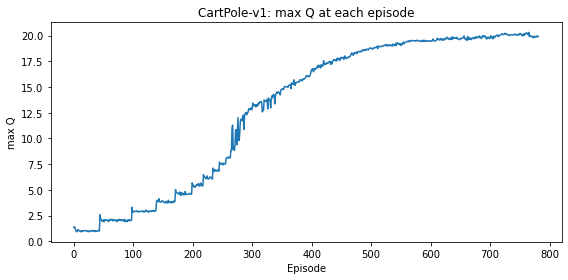

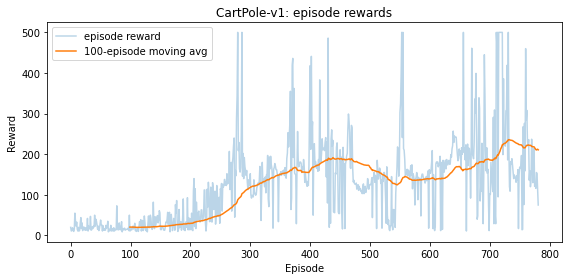

In [7]:
import matplotlib.pyplot as plt

def moving_avg(x, w=100):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")

# (i) Max Q vs. episode
plt.figure(figsize=(8, 4))
plt.plot(max_qs)
plt.xlabel("Episode")
plt.ylabel("max Q")
plt.title("CartPole-v1: max Q at each episode")
plt.tight_layout()
plt.savefig("cartpole_maxq.png", dpi=150)
plt.show()

# (ii) Episode reward vs. episode, with moving average
ma_r = moving_avg(rewards)
plt.figure(figsize=(8, 4))
plt.plot(rewards, alpha=0.3, label="episode reward")
plt.plot(range(99, len(rewards)), ma_r, label="100-episode moving avg")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("CartPole-v1: episode rewards")
plt.legend()
plt.tight_layout()
plt.savefig("cartpole_rewards.png", dpi=150)
plt.show()

In [6]:
# Rolling out 500 episodes
from src.rollout_test import rollout

In [7]:
# Defining environment
import gymnasium as gym

env = gym.make("CartPole-v1")

In [8]:
# Loading in network
import torch
from src.cartpole.model import CartpoleDQN
from pathlib import Path

path = Path("src/cartpole/output/cartpole_dqn.pt")
state_dict = torch.load(path, map_location="cpu")

model = CartpoleDQN()
model.load_state_dict(state_dict)

<All keys matched successfully>

In [9]:
scores = rollout(env, model)

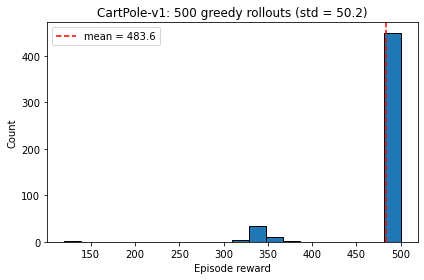

mean = 483.63, std = 50.16


In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(scores, bins=20, edgecolor="black")
plt.axvline(np.mean(scores), color="red", linestyle="--", label=f"mean = {np.mean(scores):.1f}")
plt.xlabel("Episode reward")
plt.ylabel("Count")
plt.title(f"CartPole-v1: 500 greedy rollouts (std = {np.std(scores):.1f})")
plt.legend()
plt.tight_layout()
plt.savefig("cartpole_hist.png", dpi=150)
plt.show()

print(f"mean = {np.mean(scores):.2f}, std = {np.std(scores):.2f}")

In [11]:
np.mean(np.array(scores) == 500)

0.9

In Cartpole-v1, the maximum number of timesteps is 500. So, in about 91% of games, we are able to balance the pole all the way to the end. That is, we are able to balance the pole upright for 500 time steps.

## MsPacman-v5

In [3]:
import numpy as np

data = np.load('src/mspacman/output/pacman_outputs_run_1.npz')

In [4]:
data.files

['rewards', 'max_qs']

In [5]:
rewards = data['rewards']
max_qs = data['max_qs']

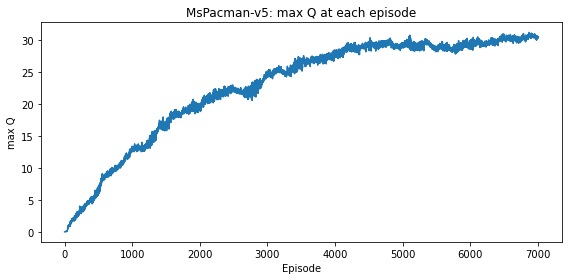

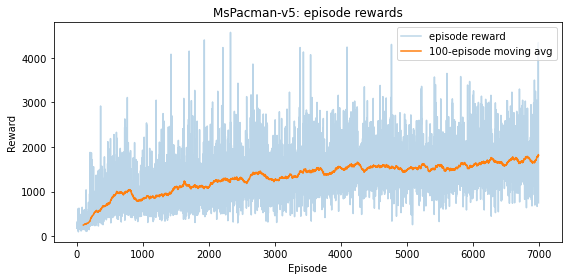

In [6]:
import matplotlib.pyplot as plt

def moving_avg(x, w=100):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")

# (i) Max Q vs. episode
plt.figure(figsize=(8, 4))
plt.plot(max_qs)
plt.xlabel("Episode")
plt.ylabel("max Q")
plt.title("MsPacman-v5: max Q at each episode")
plt.tight_layout()
plt.savefig("pacman_maxq.png", dpi=150)
plt.show()

# (ii) Episode reward vs. episode, with moving average
ma_r = moving_avg(rewards)
plt.figure(figsize=(8, 4))
plt.plot(rewards, alpha=0.3, label="episode reward")
plt.plot(range(99, len(rewards)), ma_r, label="100-episode moving avg")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("MsPacman-v5: episode rewards")
plt.legend()
plt.tight_layout()
plt.savefig("pacman.png", dpi=150)
plt.show()

In [6]:
# Rolling out 500 episodes
from src.rollout_test import rollout_pacman

# Defining environment
import gymnasium as gym
import ale_py

env = gym.make("ALE/MsPacman-v5")

A.L.E: Arcade Learning Environment (version 0.11.2+ecc1138)
[Powered by Stella]


In [7]:
# Loading in network
import torch
from src.mspacman.model import PacmanDQN
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

path = Path("src/mspacman/output/pacman_dqn_final_run_1.pt")
state_dict = torch.load(path, map_location=device)

model = PacmanDQN().to(device)
model.load_state_dict(state_dict)

cuda


<All keys matched successfully>

In [8]:
scores = rollout_pacman(env, model, device)

100%|██████████| 500/500 [15:07<00:00,  1.81s/it]


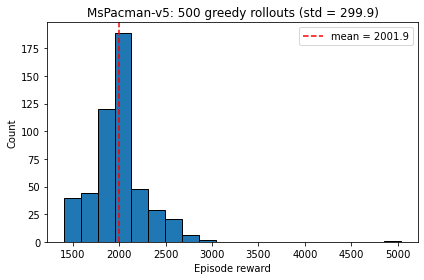

mean = 2001.92, std = 299.93


In [9]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(scores, bins=20, edgecolor="black")
plt.axvline(np.mean(scores), color="red", linestyle="--", label=f"mean = {np.mean(scores):.1f}")
plt.xlabel("Episode reward")
plt.ylabel("Count")
plt.title(f"MsPacman-v5: 500 greedy rollouts (std = {np.std(scores):.1f})")
plt.legend()
plt.tight_layout()
plt.savefig("pacman_hist.png", dpi=150)
plt.show()

print(f"mean = {np.mean(scores):.2f}, std = {np.std(scores):.2f}")

## Non-Standard Plots

In [2]:
import numpy as np
from src.validations.q_vs_actual import collect_cartpole, collect_pacman, plot_q_vs_return, animate_q_vs_return, plot_prediction_error

In [3]:
import gymnasium as gym
# Loading in network
import torch
from src.cartpole.model import CartpoleDQN
from pathlib import Path

env_cartpole = gym.make("CartPole-v1")

path = Path("src/cartpole/output/cartpole_dqn.pt")
state_dict = torch.load(path, map_location="cpu")

model_cartpole = CartpoleDQN()
model_cartpole.load_state_dict(state_dict)

<All keys matched successfully>

In [12]:
p, a, lens = collect_cartpole(env_cartpole, model_cartpole)
animate_q_vs_return(p, a, lens, "cartpole_q_dynamics.gif", title="CartPole")

2026-11-11 03:04:00,961 | INFO | Animation.save using <class 'matplotlib.animation.PillowWriter'>


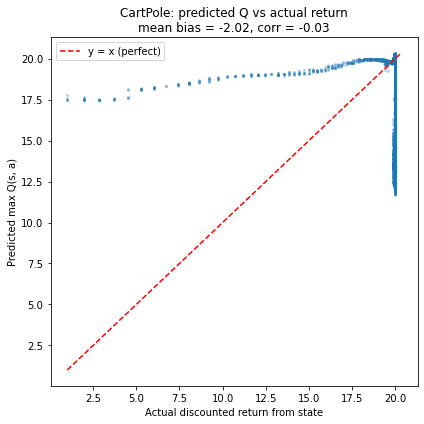

CartPole: predicted Q vs actual return: bias (Q - G) = -2.023, corr = -0.030, n = 39267


In [13]:
plot_q_vs_return(p, a, "CartPole: predicted Q vs actual return", "cartpole_q_vs_return.png")

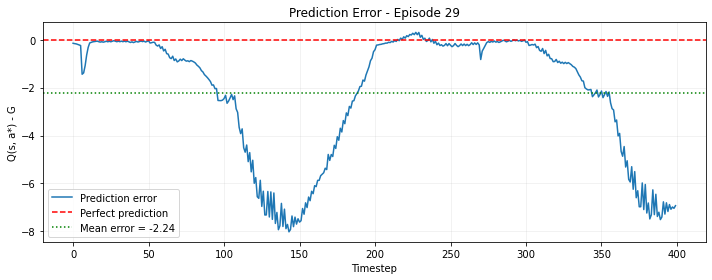

Episode 29
Mean error: -2.238
MAE: 2.252
RMSE: 3.452


In [14]:
plot_prediction_error(
    p, a, lens,
    episode=28,
    fname="prediction_error_cartpole.png"
)

In [4]:
from src.mspacman.model import PacmanDQN
env_pacman = gym.make("ALE/MsPacman-v5")

path = Path("src/mspacman/output/pacman_dqn_final_run_1.pt")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
state_dict = torch.load(path, map_location=device)

model_pacman = PacmanDQN().to(device)
model_pacman.load_state_dict(state_dict)
model_pacman.eval()

A.L.E: Arcade Learning Environment (version 0.11.2+ecc1138)
[Powered by Stella]


PacmanDQN(
  (conv): Sequential(
    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
  )
  (fc): Sequential(
    (0): Linear(in_features=2688, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=9, bias=True)
  )
)

In [5]:
p, a, lens = collect_pacman(env_pacman, model_pacman, device)
animate_q_vs_return(p, a, lens, "pacman_q_dynamics.gif", title="MsPacman")

2026-11-11 13:26:29,715 | INFO | Animation.save using <class 'matplotlib.animation.PillowWriter'>


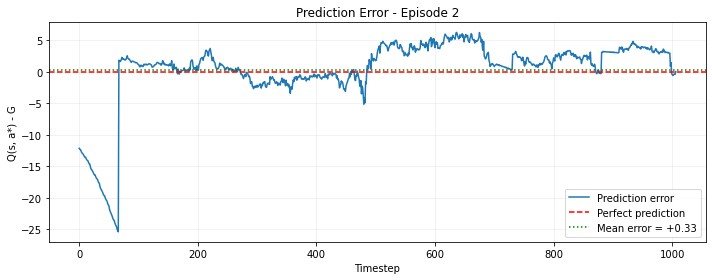

Episode 2
Mean error: +0.334
MAE: 3.318
RMSE: 5.454


In [6]:
plot_prediction_error(
    p, a, lens,
    episode=1,
    fname="prediction_error_pacman.png"
)